# Rock or rocket stage? Sunlight pressure as a mass meter

**The question.** On 17 September 2020 Pan-STARRS found a faint object, 2020 SO, on an orbit
around the Sun that looked almost exactly like the Earth's: $a \approx 1.0$ au, $e \approx 0.03$, an inclination
of a fraction of a degree. Natural asteroids rarely have orbits that Earth-like. Paul Chodas
(JPL) ran the orbit backwards and found that it had passed close to the Earth in late 1966,
just when the Surveyor 2 lunar lander was launched. In November 2020 the Earth captured it
for four months, and the fits showed what clinched the identification: sunlight was pushing it.
The push from sunlight on a body is proportional to its **area-to-mass ratio** $A/m$. A rock a
few metres across has $A/m \sim 10^{-4}$–$10^{-3}$ m²/kg. An empty rocket stage, a thin-walled
stainless-steel tank 3 m wide and 10 m long that weighs about two tonnes, has a ratio ten to
thirty times larger. The orbit becomes a set of scales.

This notebook weighs 2020 SO from its astrometry alone:

1. Fit it with gravity only, then with a radial radiation-pressure term
   $A_1 (1\,\mathrm{au}/r)^2$ (`nongrav="srp"`), and see what the extra parameter explains.
2. Turn the fitted $A_1$ into an area-to-mass ratio and compare it with JPL's solution and with
   the size and mass of a Centaur upper stage.
3. Run the same procedure on a **control**, 2020 CD3. It is a natural metre-sized asteroid that
   the Earth also captured, from 2018 to 2020, and its radiation-pressure signal was measured by
   Fedorets et al. (2020).

Two complications make this a harder case than the other notebooks. The MPC no longer
distributes the object's astrometry, and four months inside the Earth's sphere of influence, with
a perigee of about 50,000 km, test both the force model and the fit.

In [1]:
import warnings
import numpy as np
import matplotlib.pyplot as plt
import pyroorb

pyroorb.load_settings()       # the .env settings file (data folders), before the first fit

# Future UTC dates make astropy warn that leap seconds are not yet known; harmless here.
warnings.filterwarnings("ignore", message=".*dubious year.*")
plt.rcParams.update({"figure.figsize": (8, 4.5), "figure.dpi": 110, "axes.grid": True,
                     "grid.alpha": 0.3})
print("PyRoOrb", pyroorb.__version__)

PyRoOrb 0.9.1


## 1. The astrometry: the MPC no longer has it

Once 2020 SO was identified as a rocket stage, the MPC reclassified it as an artificial object
(February 2021). It withdrew the designation and the observations with it, so
`fetch_observations("2020 SO")` gets nothing back. (The MPC's API answers an unknown designation
with a server error, which PyRoOrb reports as a failed fetch.)

The observations are not lost, though. Bill Gray (Project Pluto, the author of Find_Orb) keeps a
"pseudo-MPEC" for the object, with every observation in the MPC's 80-column format, as of
31 January 2021. We read it straight from that page. `read_observations` accepts the text itself,
so nothing is written to disk. JPL's final solution used 602 observations up to March 2021, so
this set lacks the last few weeks.

In [2]:
import html, re, urllib.request
from collections import Counter
from astropy.time import Time

try:
    pyroorb.fetch_observations("2020 SO")
except pyroorb.FetchError as err:
    print("MPC:", str(err)[:100], "...")

URL = "https://www.projectpluto.com/pluto/mpecs/66084b.htm"
page = html.unescape(re.sub(r"<[^>]+>", "", urllib.request.urlopen(URL, timeout=60).read().decode("utf-8", "replace")))
lines = [l for l in page.splitlines() if len(l) == 80 and l[5:12] == "K20S00O"]   # packed 2020 SO
allobs = pyroorb.read_observations("\n".join(lines) + "\n")
jd_all = np.array([o["jd_utc"] for o in allobs])
print(f"{len(lines)} 80-column lines -> {len(allobs)} observations (a roving observer's position line pairs with its "
      f"observation) from {len(set(o['obscode'] for o in allobs))} stations,\n"
      f"{Time(jd_all.min(), format='jd').iso[:10]} to {Time(jd_all.max(), format='jd').iso[:10]}")
print("most observations:", ", ".join(f"{k} ({n})" for k, n in Counter(o["obscode"] for o in allobs).most_common(6)))

could not reach the MPC for 2020 SO: ADES: HTTPError: HTTP Error 500: INTERNAL SERVER ERROR


MPC: the MPC did not answer for 2020 SO (ADES: HTTPError: HTTP Error 500: INTERNAL SERVER ERROR) -- a tra ...


592 80-column lines -> 590 observations (a roving observer's position line pairs with its observation) from 42 stations,
2020-08-19 to 2021-01-31
most observations: I52 (121), 033 (51), 703 (41), G96 (26), V39 (26), 204 (24)


## 2. Gravity alone, on the whole arc

First the plain fit: the Sun, the planets and the Moon (DE440), with no other force.

gravity only: 259/590 observations kept, rms 0.50"


automatic model choice: gravity only
  dates           used   median |O-C|
  2020-08 16-    0/  7       13.5"
  2020-09 1-15   0/  2       11.0"
  2020-09 16-    0/ 28        9.3"
  2020-10 1-15   0/ 59        4.8"
  2020-10 16-    5/ 23        3.2"
  2020-11 1-15 101/103        0.4"
  2020-11 16-  153/183        0.6"
  2020-12 1-15   0/ 88       79.0"
  2020-12 16-    0/ 39       85.0"
  2021-01 1-15   0/ 48      151.4"
  2021-01 16-    0/ 10     1031.5"


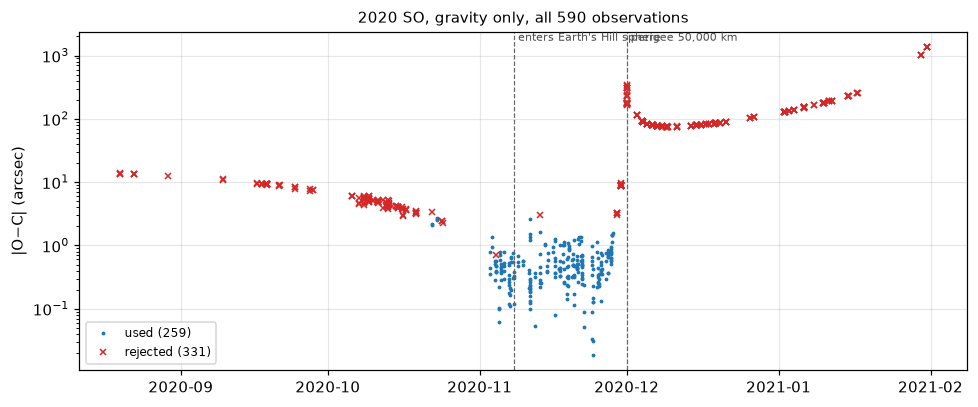

In [3]:
grav_all = pyroorb.fit_orbit(allobs, designation="2020 SO", nongrav="none")
print(f"gravity only: {grav_all.n_observations()}/{grav_all.n_total_observations()} observations kept, "
      f"rms {grav_all.rms_residual():.2f}\"")

auto_all = pyroorb.fit_orbit(allobs, designation="2020 SO")          # nongrav="auto", the default
print(f"automatic model choice: {auto_all.nongrav_model or 'gravity only'}")


def by_halfmonth(fit):
    rows = {}
    for r in fit.residuals():
        t = Time(r["jd_utc"], format="jd").datetime
        key = f"{t:%Y-%m} {'1-15' if t.day <= 15 else '16-'}"
        d = rows.setdefault(key, [0, 0, []])
        d[0] += 1; d[1] += r["included"]; d[2].append(np.hypot(r["d_ra_arcsec"], r["d_dec_arcsec"]))
    print(f"  {'dates':12s} {'used':>7s}   median |O-C|")
    for k in sorted(rows):
        n, ni, t = rows[k]
        print(f"  {k:12s} {ni:3d}/{n:3d}   {np.median(t):8.1f}\"")


by_halfmonth(grav_all)

EVENTS = {"enters Earth's Hill sphere": "2020-11-08", "perigee 50,000 km": "2020-12-01"}


def residual_panel(ax, fit, title):
    res = fit.residuals()
    t = Time([r["jd_utc"] for r in res], format="jd").datetime
    tot = np.array([np.hypot(r["d_ra_arcsec"], r["d_dec_arcsec"]) for r in res])
    inc = np.array([r["included"] for r in res])
    ax.semilogy(np.array(t)[inc], tot[inc], ".", ms=3, label=f"used ({inc.sum()})")
    ax.semilogy(np.array(t)[~inc], tot[~inc], "x", ms=4, color="C3", label=f"rejected ({(~inc).sum()})")
    for name, d in EVENTS.items():
        ax.axvline(Time(d).datetime, color="0.4", ls="--", lw=0.8)
        ax.text(Time(d).datetime, ax.get_ylim()[1], " " + name, fontsize=7, va="top", color="0.3")
    ax.set_ylabel("|O−C| (arcsec)"); ax.set_title(title, fontsize=10); ax.legend(fontsize=8, loc="lower left")


fig, ax = plt.subplots(figsize=(9, 3.8))
residual_panel(ax, grav_all, "2020 SO, gravity only, all 590 observations")
plt.tight_layout(); plt.show()

Gravity alone cannot follow 2020 SO. Even the best gravity orbit fits only one month of the
five, the first three weeks of November. The fit keeps 259 observations at a fine rms and rejects
the other 331: by arcminutes after the close approach, and by 3 to 14 arcseconds before
November. Gravity-only fits of a body pushed by an unmodelled force often behave like this. They
do not show a bad rms. They show a short arc and a long list of "outliers".

The automatic choice (`nongrav="auto"`) does not help here. PyRoOrb's automatic search for a
non-gravitational force on an asteroid looks for Yarkovsky drift, which takes several
apparitions to show, and it only runs on multi-apparition orbits. It does not try radiation
pressure on a single-apparition object, so the fit stays gravity-only. A temporarily captured
object is always a one-apparition case, so we name the model ourselves.

## 3. Before the close approach: gravity against sunlight

The close approach on 1 December, 50,000 km from the Earth's centre, amplifies every small error
in the model. We start with the part of the arc before it (to 28 November). Sunlight's push has
four months there to build up, and the geometry is still gentle. `nongrav="srp"` adds one
parameter to the fit, a radial acceleration $A_1$ at 1 au that falls off as $1/r^2$.

In [4]:
pre = allobs.select(stop="2020-11-28")
grav = pyroorb.fit_orbit(pre, designation="2020 SO", nongrav="none")
srp_forced = pyroorb.fit_orbit(pre, designation="2020 SO", nongrav="srp")


def chi2(fit, mask=None):
    "Weighted chi^2 over the included observations (or `mask`), and the number of residuals (2 per observation)."
    res = fit.residuals()
    m = np.array([r["included"] for r in res]) if mask is None else mask
    z = np.array([(r["d_ra_arcsec"] / r["sigma_ra"]) ** 2 + (r["d_dec_arcsec"] / r["sigma_dec"]) ** 2 for r in res])
    return z[m].sum(), 2 * int(m.sum())


for name, f in (("gravity", grav), ("srp", srp_forced)):
    c, N = chi2(f)
    print(f"{name:8s} {f.n_observations()}/{f.n_total_observations()} kept, rms {f.rms_residual():.3f}\", "
          f"chi2 {c:6.1f} over N = {N} residuals  {f.nongrav_params}")
c0, N = chi2(grav); c1, _ = chi2(srp_forced)
print(f"BIC gain for one extra parameter: {c0 - c1:.0f} - ln({N}) = {c0 - c1 - np.log(N):.0f}")

gravity  252/370 kept, rms 0.850", chi2  448.9 over N = 504 residuals  {}
srp      252/370 kept, rms 0.428", chi2  134.9 over N = 504 residuals  {'A1': 3.883599030182818e-09}
BIC gain for one extra parameter: 314 - ln(504) = 308


On the same 252 observations, the radiation-pressure term halves the rms. The weighted χ²
drops by more than 300, while the Bayesian information criterion charges only $\ln N \approx 6$
for the extra parameter. A ΔBIC above 10 already counts as decisive.

There is a catch, though. A forced model (`nongrav="srp"`) is fitted **on the gravity fit's
observation set**. The 118 observations that gravity threw out stay out, even though most of
them now fit. To give both models the same chance, we apply one simple rule to each: *include
every observation within 3σ of the current orbit, refit, and repeat until the set stops
changing*. `pyroorb.refit(fit, include, nongrav=...)` solves an orbit on exactly the
observations marked in `include`, with no rejection of its own. With gravity alone the same
rule keeps the set gravity already had.

gravity  259/370 observations within 3 sigma, rms 0.867"
srp      361/370 observations within 3 sigma, rms 0.449"
on the same 361 observations: chi2 gravity 5249, srp 299;  delta BIC = 4944



A1 = 3.990e-09  (-8.4e-11 / +7.2e-11) au/day^2 at 1 au, 47 sigma from zero


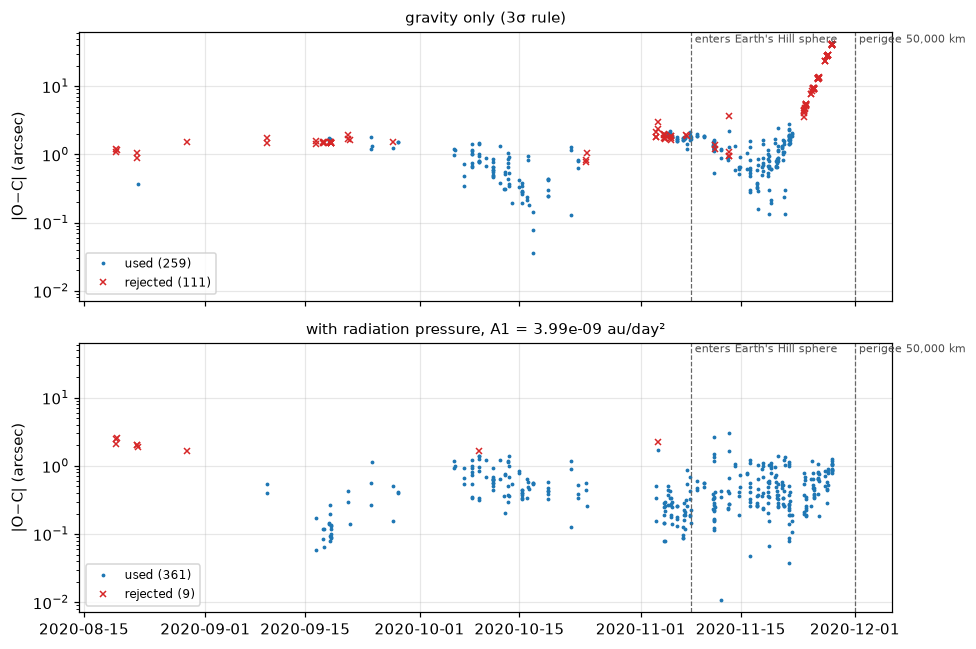

In [5]:
def sigmas(fit):
    return np.array([r["resid_sigmas"] for r in fit.residuals()])


def reinclude(fit, refit, rounds=8):
    "Keep every observation within 3 sigma of the current orbit, refit, until the set settles."
    mask = None
    for _ in range(rounds):
        new = sigmas(fit) < 3.0
        if mask is not None and np.array_equal(new, mask):
            break
        mask = new
        fit = refit(mask)
    return fit, mask


def srp_refit(gravity_fit, model="srp"):
    return lambda m: pyroorb.refit(gravity_fit, m, nongrav=model)


def gravity_refit(gravity_fit):
    return lambda m: pyroorb.refit(gravity_fit, m, nongrav="none")


srp, m_srp = reinclude(srp_forced, srp_refit(grav))
grav3, m_grav = reinclude(grav, gravity_refit(grav))
for name, f, m in (("gravity", grav3, m_grav), ("srp", srp, m_srp)):
    print(f"{name:8s} {m.sum()}/{len(m)} observations within 3 sigma, rms {f.rms_residual():.3f}\"")

c0, N = chi2(pyroorb.refit(grav, m_srp, nongrav="none"), m_srp)    # gravity, best fit to srp's set
c1, _ = chi2(srp, m_srp)
print(f"on the same {m_srp.sum()} observations: chi2 gravity {c0:.0f}, srp {c1:.0f};  delta BIC = {c0 - c1 - np.log(N):.0f}")

A1 = srp.nongrav_params["A1"]
lo, hi = srp.rational_nongrav_intervals()["A1"]
print(f"\nA1 = {A1:.3e}  (-{lo:.1e} / +{hi:.1e}) au/day^2 at 1 au, {A1 / lo:.0f} sigma from zero")

fig, axes = plt.subplots(2, 1, figsize=(9, 6), sharex=True, sharey=True)
residual_panel(axes[0], grav3, "gravity only (3σ rule)")
residual_panel(axes[1], srp, f"with radiation pressure, A1 = {A1:.2e} au/day²")
plt.tight_layout(); plt.show()

With sunlight in the model, 361 of the 370 pre-perigee observations fit within 3σ at an rms of
0.45″. Gravity still keeps only about 260 of them. The seven Pan-STARRS and Catalina precovery
positions from 19–29 August stay about 2″ off. Find_Orb's own residuals for them are 3–3.5″ in
each coordinate (they are listed on the same page), so they are left out.
The radial push is detected at about 50σ, by its formal (profile-likelihood) interval.

## 4. How solid is $A_1$?

A 2% formal uncertainty assumes the model is right: a constant, purely radial push that falls
off as $1/r^2$. A tumbling cylinder presents a changing cross-section, and its reflection is not
purely radial. The honest test is to change the data and the model and watch $A_1$ move: we
cut the arc at different dates, drop the August precoveries, and free the transverse and normal
components (`srp3`, $A_1, A_2, A_3$).

In [6]:
variants = {}
for label, start, stop in (("to 10 Nov", None, "2020-11-10"), ("to 20 Nov", None, "2020-11-20"),
                           ("to 28 Nov", None, "2020-11-28"), ("1 Sep - 28 Nov", "2020-09-01", "2020-11-28")):
    if stop == "2020-11-28" and start is None:
        f, m = srp, m_srp                                            # the fit above
    else:
        sub = allobs.select(start=start, stop=stop)
        g = pyroorb.fit_orbit(sub, designation="2020 SO", nongrav="none")
        f, m = reinclude(pyroorb.fit_orbit(sub, designation="2020 SO", nongrav="srp"), srp_refit(g))
    variants[f"srp, {label}"] = (f, m)
f3, m3 = reinclude(pyroorb.refit(grav, m_srp, nongrav="srp3"), srp_refit(grav, "srp3"))
variants["srp3, to 28 Nov"] = (f3, m3)

print(f"{'model, arc':22s} {'obs':>4s} {'rms':>6s}   A1 (1e-9 au/d^2)    A2, A3 (1e-10)")
for name, (f, m) in variants.items():
    p, iv = f.nongrav_params, f.rational_nongrav_intervals()
    extra = "  ".join(f"{k} {p[k] / 1e-10:+.1f}±{max(iv[k]) / 1e-10:.1f}" for k in ("A2", "A3") if k in p)
    print(f"{name:22s} {m.sum():4d} {f.rms_residual():6.3f}   {p['A1'] / 1e-9:5.2f} ± {max(iv['A1']) / 1e-9:.2f}      {extra}")
a1_values = np.array([f.nongrav_params["A1"] for f, _ in variants.values()])
print(f"\nspread over these variants: A1 = {a1_values.min():.2e} to {a1_values.max():.2e} au/day^2")

model, arc              obs    rms   A1 (1e-9 au/d^2)    A2, A3 (1e-10)
srp, to 10 Nov          181  0.316    2.81 ± 0.38      


srp, to 20 Nov          268  0.393    4.44 ± 0.25      
srp, to 28 Nov          361  0.449    3.99 ± 0.08      
srp, 1 Sep - 28 Nov     360  0.445    3.99 ± 0.08      


srp3, to 28 Nov         368  0.360    2.88 ± 0.12      A2 -2.7±0.3  A3 +2.4±0.2

spread over these variants: A1 = 2.81e-09 to 4.44e-09 au/day^2


The radial term is always there and always positive. Its size, though, moves by about ±20%
between variants, about ten times its formal σ. Cutting the arc at different November dates
changes $A_1$ between 2.8 and 4.4 × 10⁻⁹. Freeing $A_2, A_3$ (srp3) improves the rms and keeps
368 of 370 observations. It finds transverse and normal components about a tenth of the radial
one, and it lowers $A_1$ to 2.9 × 10⁻⁹. Some of the light leaves the body sideways, as you would
expect from a long cylinder. The constant-$A$ model is a simplification, and this spread, not the
formal σ, is the honest uncertainty: **$A_1 \approx (3$–$4.4) \times 10^{-9}$ au/day²**.

### Against JPL and Find_Orb

JPL's precomputed trajectory for the object (Horizons, `-54054450`) is a fit to all 602
observations through March 2021. Its model goes further than ours: $A_1/r^2$ plus two "gas jet"
terms (the Chesley & Yeomans 2005 rotating-jet model), included to absorb the asymmetry and time
variability a tumbling stage shows. The Find_Orb fit on the page we read has $A_1, A_2, A_3$
over the full arc to 31 January. Both are read live below.

JPL: 1966-084B ("2020 SO") | # obs: 602 (2020-2021)
  A1 = 3.557e-09 au/day^2 (+ jets AJ1 = 1.54e-09, AJ2 = -3.23e-09)
Find_Orb (pseudo-MPEC, to 31 Jan): A1 = 2.87e-09, A2 = -1.01e-11, A3 = -9.47e-11
PyRoOrb srp, to 28 Nov: A1 = 3.99e-09  ->  +12% vs JPL; variants span -21% to +25%


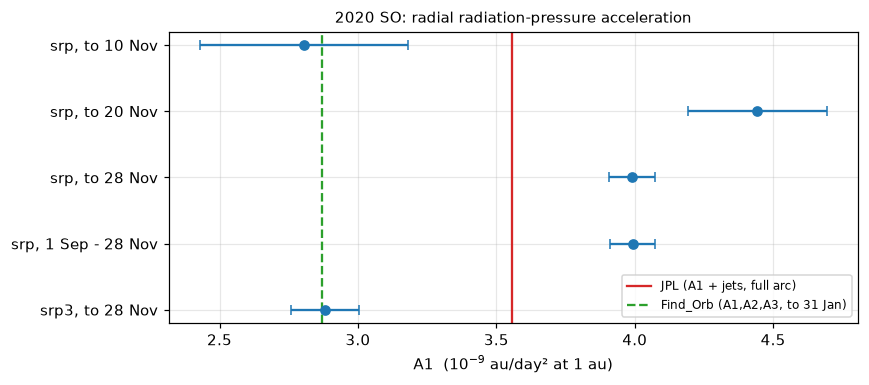

In [7]:
hz = urllib.request.urlopen("https://ssd.jpl.nasa.gov/api/horizons.api?format=text&COMMAND='-54054450'"
                            "&OBJ_DATA=YES&MAKE_EPHEM=NO", timeout=60).read().decode()


def grab(name, text):
    m = re.search(rf"\b{name}\s*[=:]\s*([-+0-9.Ee]+)", text)
    return float(m.group(1)) if m else None


jpl = {k: grab(k, hz) for k in ("A1", "AJ1", "AJ2", "H")}
fo_srp = {k: grab(k, page) for k in ("A1", "A2", "A3")}
print("JPL:", re.search(r"JPL/HORIZONS\s+(.*?)\s{2,}", hz).group(1), "|", re.search(r"# obs: .*", hz).group(0))
print(f"  A1 = {jpl['A1']:.3e} au/day^2 (+ jets AJ1 = {jpl['AJ1']:.2e}, AJ2 = {jpl['AJ2']:.2e})")
print(f"Find_Orb (pseudo-MPEC, to 31 Jan): A1 = {fo_srp['A1']:.2e}, A2 = {fo_srp['A2']:.2e}, A3 = {fo_srp['A3']:.2e}")
print(f"PyRoOrb srp, to 28 Nov: A1 = {A1:.2e}  ->  {100 * (A1 / jpl['A1'] - 1):+.0f}% vs JPL; "
      f"variants span {100 * (a1_values.min() / jpl['A1'] - 1):+.0f}% to {100 * (a1_values.max() / jpl['A1'] - 1):+.0f}%")

fig, ax = plt.subplots(figsize=(8, 3.6))
for j, (name, (f, _)) in enumerate(variants.items()):
    ax.errorbar(f.nongrav_params["A1"] / 1e-9, j, xerr=max(f.rational_nongrav_intervals()["A1"]) / 1e-9,
                fmt="o", capsize=3, color="C0")
ax.axvline(jpl["A1"] / 1e-9, color="C3", label="JPL (A1 + jets, full arc)")
ax.axvline(fo_srp["A1"] / 1e-9, color="C2", ls="--", label="Find_Orb (A1,A2,A3, to 31 Jan)")
ax.set_yticks(range(len(variants)), list(variants)); ax.invert_yaxis()
ax.set_xlabel("A1  ($10^{-9}$ au/day² at 1 au)"); ax.legend(fontsize=8, loc="lower right")
ax.set_title("2020 SO: radial radiation-pressure acceleration", fontsize=10)
plt.tight_layout(); plt.show()

JPL's $A_1$ falls inside the spread of our variants. Our single-arc srp value is about 12% above
it and the srp3 value about 15% below. Find_Orb's three-parameter value is lower again, at
2.9 × 10⁻⁹. Three programs, three force models and three data spans agree on the size of the push
to within about ±20%, and that is enough for the question we are asking.

## 5. A prediction check: the 1 December close approach

A model that has really captured the push should predict what came next. We propagate both
pre-perigee orbits (gravity only, and with radiation pressure) through the close approach of
1 December, which neither fit has seen, and compare them with JPL's trajectory of the object.

JPL trajectory            perigee  50,486 km at 2020-12-01 08:48 UTC
gravity only              perigee  50,503 km at 2020-12-01 08:38 UTC;  largest difference from JPL's geocentric distance over the two days:   939 km
radiation pressure (srp)  perigee  50,477 km at 2020-12-01 08:48 UTC;  largest difference from JPL's geocentric distance over the two days:    31 km
srp3                      perigee  50,488 km at 2020-12-01 08:48 UTC;  largest difference from JPL's geocentric distance over the two days:    13 km


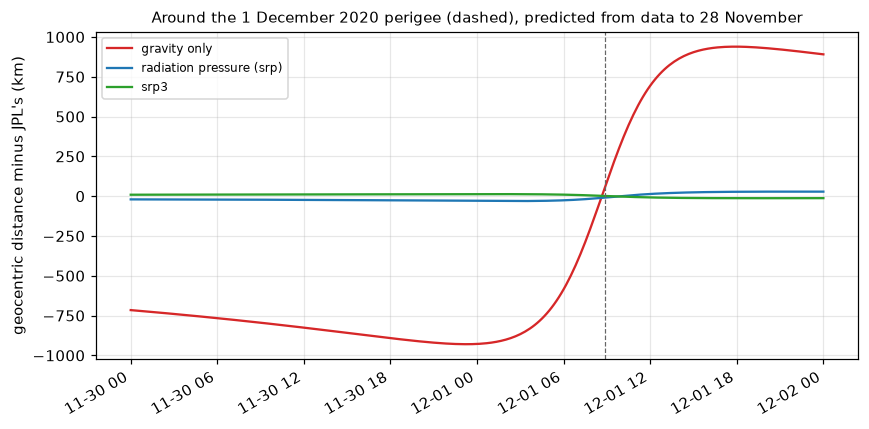

In [8]:
AU_KM = 1.495978707e8
hzv = urllib.request.urlopen("https://ssd.jpl.nasa.gov/api/horizons.api?format=text&COMMAND='-54054450'"
                             "&OBJ_DATA=NO&MAKE_EPHEM=YES&EPHEM_TYPE=VECTORS&CENTER='500@399'"
                             "&START_TIME='2020-11-30'&STOP_TIME='2020-12-02'&STEP_SIZE='10m'"
                             "&VEC_TABLE='1'&CSV_FORMAT=YES&OUT_UNITS='KM-S'", timeout=60).read().decode()
rows = [l.split(",") for l in hzv.split("$$SOE")[1].split("$$EOE")[0].strip().splitlines()]
t_tdb = Time([float(r[0]) for r in rows], format="jd", scale="tdb")
d_jpl = np.linalg.norm(np.array([[float(x) for x in r[2:5]] for r in rows]), axis=1)
earth = pyroorb.body_states("earth", t_tdb)[:, :3]

fig, ax = plt.subplots(figsize=(8, 4))
k = np.argmin(d_jpl)
print(f"{'JPL trajectory':25s} perigee {d_jpl[k]:7,.0f} km at {t_tdb[k].utc.iso[:16]} UTC")
for name, f, c in (("gravity only", grav3, "C3"), ("radiation pressure (srp)", srp, "C0"), ("srp3", f3, "C2")):
    d = np.linalg.norm(pyroorb.propagate(f, t_tdb)[:, :3] - earth, axis=1) * AU_KM
    k = np.argmin(d)
    print(f"{name:25s} perigee {d[k]:7,.0f} km at {t_tdb[k].utc.iso[:16]} UTC;  largest difference from JPL's "
          f"geocentric distance over the two days: {np.max(np.abs(d - d_jpl)):5,.0f} km")
    ax.plot(t_tdb.datetime, d - d_jpl, color=c, label=name)
ax.axvline(t_tdb[np.argmin(d_jpl)].datetime, color="0.4", ls="--", lw=0.8)
ax.set_ylabel("geocentric distance minus JPL's (km)"); ax.legend(fontsize=8)
ax.set_title("Around the 1 December 2020 perigee (dashed), predicted from data to 28 November", fontsize=10)
fig.autofmt_xdate(); plt.tight_layout(); plt.show()

All three orbits put the perigee near 50,500 km; the minimum distance alone hardly tells them
apart. *When* it happens, and the whole approach and departure, does. The gravity-only orbit
runs about ten minutes early and is up to roughly a thousand kilometres off in distance, while
the orbits with sunlight's push stay within a few tens of kilometres of JPL's trajectory, which
was fitted to all the data, including the weeks after the perigee.

## 6. Through the close approach: where a constant push stops working

After the perigee, can one constant force model follow the object? We extend the arc step by
step. At each step every observation up to the new end date is included and none is rejected,
and `pyroorb.refit` starts each step from the previous step's solution. This is a stress test
of the models, not a production fit.

In [9]:
ends = ["2020-11-28", "2020-12-01", "2020-12-04", "2020-12-10", "2020-12-31", "2021-01-15", "2021-02-01"]
print(f"{'model':5s} {'arc to':10s} {'obs':>4s} {'rms':>6s} {'<3σ':>5s}   A1 (1e-9 au/d^2)")
for model in ("srp", "srp3"):
    f = None
    for e in ends:
        mask = jd_all < Time(e).jd
        f = pyroorb.refit(grav_all if f is None else f, mask, nongrav=model)
        print(f"{model:5s} {e:10s} {mask.sum():4d} {f.rms_residual():6.2f} {np.mean(sigmas(f)[mask] < 3):5.0%}   "
              f"{f.nongrav_params['A1'] / 1e-9:.2f}")

model arc to      obs    rms   <3σ   A1 (1e-9 au/d^2)


srp   2020-11-28  370   0.55   97%   3.94
srp   2020-12-01  405   0.78   91%   4.17


srp   2020-12-04  420   1.33   80%   3.64


srp   2020-12-10  477   1.42   66%   3.25


srp   2020-12-31  532   1.37   65%   2.93


srp   2021-01-15  574   1.37   70%   2.81


srp   2021-02-01  590   2.01   63%   2.83
srp3  2020-11-28  370   0.37   99%   2.94


srp3  2020-12-01  405   0.46   99%   2.85
srp3  2020-12-04  420   0.49   99%   3.15


srp3  2020-12-10  477   0.47   99%   3.13
srp3  2020-12-31  532   0.49   99%   3.05


srp3  2021-01-15  574   0.90   91%   3.15


srp3  2021-02-01  590   3.40   43%   2.98


The one-parameter radial model loses the object within days of the perigee: by 10 December a
third of the observations are beyond 3σ. The three-component model (radial, transverse and
normal, all constant) follows it through the 50,000 km passage and the whole of December at
0.5″. It fails in the second half of January, as the object heads for its second perigee
(2 February 2021, 220,000 km). This matches the reference fits. Find_Orb's three-parameter fit
to 31 January has an rms of 1.5″ (stated on the page), and JPL added time-varying jet terms. A
tumbling, partly specular cylinder does not feel a constant push. Through all of this, $A_1$
stays between 2.8 and 4.2 × 10⁻⁹ au/day².

## 7. From acceleration to area-to-mass ratio

Sunlight carries momentum. At 1 au its pressure on a perfect absorber is
$P_\odot = S_\odot / c = 1361\ \mathrm{W\,m^{-2}} / c = 4.54 \times 10^{-6}$ N/m². A body of
cross-section $A$ and mass $m$ that reflects part of the light feels

$$a = C_R \, \frac{S_\odot}{c}\, \frac{A}{m} \left(\frac{1\,\mathrm{au}}{r}\right)^2 ,$$

with $C_R = 1$ for a perfect absorber, up to 2 for a mirror facing the Sun. $A_1$ is exactly this
acceleration at 1 au, so $A/m = A_1 / (C_R\, S_\odot/c)$, and the reflectivity is an assumption
that the orbit cannot remove. We quote the absorber value ($C_R = 1$, the convention
Find_Orb and Fedorets et al. use) and a range for $C_R$ = 1.0–1.5.

For the stage itself: Surveyor 2 flew on Atlas-Centaur AC-7, whose Centaur-D upper stage is a
stainless-steel balloon tank 3.05 m (10 ft) in diameter. Radar ranging of 2020 SO in December
2020 ([IAA RAS](https://iaaras.ru/en/observations/echo/2020so/), Russia) found an elongated body about 10 m × 3 m. For length and empty mass we use
the closely related Centaur D-1T: length 9.6 m, inert mass 1,827 kg (*Titan IIIE/Centaur D-1T
Systems Summary*, Convair/Martin Marietta, NASA, 1973, as tabulated in Wikipedia's *Centaur
(rocket stage)* article). A tumbling convex body presents on average one quarter of its surface
area to the Sun.

In [10]:
S_SUN, C_LIGHT, AU_M, DAY_S = 1361.0, 299792458.0, 1.495978707e11, 86400.0
P_SUN = S_SUN / C_LIGHT                                    # N/m^2 at 1 au, perfect absorber
TO_MS2 = AU_M / DAY_S**2                                   # 1 au/day^2 in m/s^2


def amr(a1, c_r=1.0):
    return a1 * TO_MS2 / (c_r * P_SUN)


print(f"P_sun = {P_SUN:.3e} N/m^2;   1e-9 au/day^2 = {1e-9 * TO_MS2:.2e} m/s^2")
print(f"{'source':26s} {'A1 (m/s^2)':>11s}   A/m for C_R = 1.0 ... 1.5  (m^2/kg)")
for name, a in (("PyRoOrb srp, to 28 Nov", A1), ("PyRoOrb variants, low", a1_values.min()),
                ("PyRoOrb variants, high", a1_values.max()), ("JPL", jpl["A1"]), ("Find_Orb", fo_srp["A1"])):
    print(f"{name:26s} {a * TO_MS2:11.2e}   {amr(a):.4f} ... {amr(a, 1.5):.4f}")

r_tank, length, mass = 3.05 / 2, 9.6, 1827.0
xsec = {"end-on": np.pi * r_tank**2, "tumbling average": (2 * np.pi * r_tank**2 + 2 * np.pi * r_tank * length) / 4,
        "broadside": 2 * r_tank * length}
print("\nCentaur stage, 3.05 m x 9.6 m, 1,827 kg:")
for k, a in xsec.items():
    print(f"  {k:17s} cross-section {a:5.1f} m^2  ->  A/m = {a / mass:.4f} m^2/kg")

H_so = srp.absolute_magnitude()[0]
D_rock = 1329e3 / np.sqrt(0.14) * 10 ** (-0.2 * H_so)     # m, for a typical NEA albedo 0.14
rho_implied = 1.5 / (D_rock * amr(A1))                     # sphere: A/m = 3 / (2 rho D)
print(f"\nIf 2020 SO were a rock: H = {H_so:.1f} (JPL {jpl['H']}) -> D = {D_rock:.1f} m at albedo 0.14; "
      f"the measured A/m would need a bulk density of {rho_implied:.0f} kg/m^3 "
      f"(range {1.5 / (D_rock * amr(a1_values.max())):.0f}-{1.5 / (D_rock * amr(a1_values.min())):.0f}). "
      f"Water is 1000; a rock is 1500-3500.")

P_sun = 4.540e-06 N/m^2;   1e-9 au/day^2 = 2.00e-08 m/s^2
source                      A1 (m/s^2)   A/m for C_R = 1.0 ... 1.5  (m^2/kg)
PyRoOrb srp, to 28 Nov        8.00e-08   0.0176 ... 0.0117
PyRoOrb variants, low         5.62e-08   0.0124 ... 0.0083
PyRoOrb variants, high        8.90e-08   0.0196 ... 0.0131
JPL                           7.13e-08   0.0157 ... 0.0105
Find_Orb                      5.75e-08   0.0127 ... 0.0084

Centaur stage, 3.05 m x 9.6 m, 1,827 kg:
  end-on            cross-section   7.3 m^2  ->  A/m = 0.0040 m^2/kg
  tumbling average  cross-section  26.6 m^2  ->  A/m = 0.0146 m^2/kg
  broadside         cross-section  29.3 m^2  ->  A/m = 0.0160 m^2/kg

If 2020 SO were a rock: H = 28.9 (JPL 28.444) -> D = 5.9 m at albedo 0.14; the measured A/m would need a bulk density of 14 kg/m^3 (range 13-21). Water is 1000; a rock is 1500-3500.


The measured push gives $A/m \approx 0.012$–$0.020$ m²/kg for a perfect absorber, or roughly
0.008–0.020 m²/kg allowing for reflection. The Centaur stage's geometry gives 0.004 (end-on) to
0.016 (broadside), with 0.015 for a randomly tumbling stage. The two agree, with no free
parameter beyond the assumed reflectivity. A natural rock of 2020 SO's brightness would need a
bulk density of 10–20 kg/m³, a fiftieth to a hundredth of water's. Either 2020 SO is a hollow
structure, or the orbit is lying, and the control below tests the second possibility.

## 8. The control: 2020 CD3, a natural minimoon

2020 CD3 was found by the Catalina Sky Survey in February 2020, already in orbit around the
Earth, and left in spring 2020. Like 2020 SO it was a candidate artificial object until its
radiation-pressure signal came in small. Fedorets et al. (2020, *AJ* **160**, 277,
doi:10.3847/1538-3881/abc3bc) measured
$A/m = (0.65 \pm 0.05) \times 10^{-3}$ m²/kg (zero-albedo convention, their §4.1), which together
with its colours makes it a natural silicate body about 1.2 m across with a density of
2.1 ± 0.4 g/cm³ for an S-type albedo.

We run exactly the same procedure: fetch, gravity, `srp`, and the 3σ rule.

In [11]:
import json

cd3 = pyroorb.fetch_observations("2020 CD3")
g_cd3 = pyroorb.fit_orbit(cd3, designation="2020 CD3", nongrav="none")
s_cd3, m_cd3 = reinclude(pyroorb.fit_orbit(cd3, designation="2020 CD3", nongrav="srp"), srp_refit(g_cd3))
c0, N = chi2(pyroorb.refit(g_cd3, m_cd3, nongrav="none"), m_cd3)
c1, _ = chi2(s_cd3, m_cd3)
A1_cd3 = s_cd3.nongrav_params["A1"]
sig_cd3 = max(s_cd3.rational_nongrav_intervals()["A1"])
print(f"2020 CD3: {len(cd3)} observations; gravity rms {g_cd3.rms_residual():.3f}\" on {g_cd3.n_observations()}, "
      f"srp rms {s_cd3.rms_residual():.3f}\" on {m_cd3.sum()} (arc {s_cd3.arc_length_days():.0f} days)")
print(f"  delta BIC for A1 = {c0 - c1 - np.log(N):.0f};  A1 = {A1_cd3:.3e} ± {sig_cd3:.1e} au/day^2")
dropped = [Time(o["jd_utc"], format="jd").iso[:10] for o, keep in zip(cd3, m_cd3) if not keep]
print(f"  left out: {len(dropped)} observations, dates {sorted(set(dropped))}")

sb = json.load(urllib.request.urlopen("https://ssd-api.jpl.nasa.gov/sbdb.api?sstr=2020%20CD3&phys-par=1", timeout=60))
jp = {p["name"]: (float(p["value"]), float(p["sigma"])) for p in sb["orbit"]["model_pars"] if p["kind"] == "EST"}
print(f"JPL ({sb['orbit']['first_obs']} to {sb['orbit']['last_obs']}, {sb['orbit']['n_obs_used']} obs): "
      f"A1 = {jp['A1'][0]:.3e} ± {jp['A1'][1]:.1e};  PyRoOrb - JPL = {(A1_cd3 - jp['A1'][0]) / sig_cd3:+.1f} PyRoOrb sigma")

H_cd3 = s_cd3.absolute_magnitude()[0]
p_v, q_phase = 0.26, 0.39                                     # S-type albedo (as Fedorets et al.), phase integral for G = 0.15
D_cd3 = 1329e3 / np.sqrt(p_v) * 10 ** (-0.2 * H_cd3)
amr0 = amr(A1_cd3)                                            # zero-albedo convention
amr_true = amr0 / (1 + 4 * p_v * q_phase / 9)                 # Fedorets et al. eq. 1, sphere with Bond albedo p*q
print(f"\nA/m (zero albedo): PyRoOrb {amr0 * 1e3:.2f} ± {amr(sig_cd3) * 1e3:.2f} e-3, JPL {amr(jp['A1'][0]) * 1e3:.2f} e-3, "
      f"Fedorets et al. 0.65 ± 0.05 e-3  m^2/kg")
print(f"H = {H_cd3:.2f} -> D = {D_cd3:.2f} m at albedo {p_v};  density = {1.5 / (D_cd3 * amr_true):.0f} "
      f"(+{1.5 / (D_cd3 * amr(A1_cd3 - sig_cd3) / (1 + 4 * p_v * q_phase / 9)) - 1.5 / (D_cd3 * amr_true):.0f} "
      f"/ -{1.5 / (D_cd3 * amr_true) - 1.5 / (D_cd3 * amr(A1_cd3 + sig_cd3) / (1 + 4 * p_v * q_phase / 9)):.0f}) kg/m^3 "
      f"(Fedorets et al.: 2100 ± 400)")
print(f"\n2020 SO / 2020 CD3 area-to-mass ratio: {amr(A1) / amr0:.0f}x (range over the 2020 SO variants "
      f"{amr(a1_values.min()) / amr0:.0f}-{amr(a1_values.max()) / amr0:.0f}x)")

2020 CD3: 144 observations; gravity rms 0.402" on 132, srp rms 0.297" on 132 (arc 95 days)
  delta BIC for A1 = 50;  A1 = 1.691e-10 ± 2.8e-11 au/day^2
  left out: 12 observations, dates ['2018-05-09', '2019-01-17', '2019-01-24']


JPL (2018-05-09 to 2020-05-20, 128 obs): A1 = 1.357e-10 ± 2.5e-12;  PyRoOrb - JPL = +1.2 PyRoOrb sigma

A/m (zero albedo): PyRoOrb 0.75 ± 0.12 e-3, JPL 0.60 e-3, Fedorets et al. 0.65 ± 0.05 e-3  m^2/kg
H = 31.73 -> D = 1.18 m at albedo 0.26;  density = 1784 (+355 / -254) kg/m^3 (Fedorets et al.: 2100 ± 400)

2020 SO / 2020 CD3 area-to-mass ratio: 24x (range over the 2020 SO variants 17-26x)


The control behaves like a rock. Radiation pressure is detected (ΔBIC ≈ 50), but its $A/m$
is about 0.75 × 10⁻³ m²/kg. That is within our 1σ of both Fedorets et al. and JPL. For a
1.2 m silicate body it implies a density of about 1,800 kg/m³, against their 2,100 ± 400.
2020 SO's ratio is about 25 times larger (17–26 times across the variants).

One difference from JPL deserves a note. PyRoOrb keeps only the 2020 apparition (95 days); it
rejects the twelve 2018–2019 precovery positions, which are tens to thousands of arcseconds off
an orbit fitted to 2020. JPL's solution links them (data from 2018-05-09), and that is why its
σ is about ten times smaller. Bringing them in would mean following the minimoon's chaotic
geocentric orbit back two years through lunar encounters. A constant-$A_1$ fit does not get there
by simply extending the arc, so we leave them out and say so.

## 9. The scale

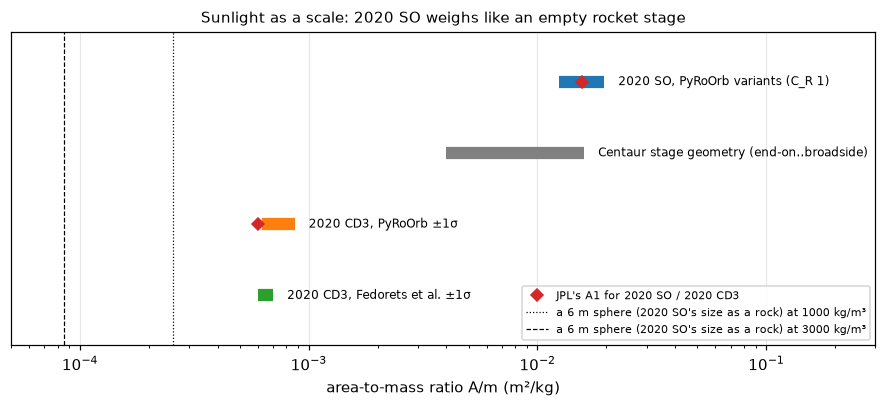

In [12]:
fig, ax = plt.subplots(figsize=(8.5, 3.8))
y = 0
for label, lo_, hi_, c in (("2020 SO, PyRoOrb variants (C_R 1)", amr(a1_values.min()), amr(a1_values.max()), "C0"),
                          ("Centaur stage geometry (end-on..broadside)", xsec["end-on"] / mass, xsec["broadside"] / mass, "0.5"),
                          ("2020 CD3, PyRoOrb ±1σ", amr(A1_cd3 - sig_cd3), amr(A1_cd3 + sig_cd3), "C1"),
                          ("2020 CD3, Fedorets et al. ±1σ", 0.60e-3, 0.70e-3, "C2")):
    ax.plot([lo_, hi_], [y, y], lw=8, color=c, solid_capstyle="butt")
    ax.text(hi_ * 1.15, y, label, va="center", fontsize=8)
    y += 1
ax.plot(amr(jpl["A1"]), 0, "D", color="C3", label="JPL's A1 for 2020 SO / 2020 CD3")
ax.plot(amr(jp["A1"][0]), 2, "D", color="C3")
for rho, ls in ((1000, ":"), (3000, "--")):
    ax.axvline(1.5 / (rho * D_rock), color="k", ls=ls, lw=0.8,
               label=f"a {D_rock:.0f} m sphere (2020 SO's size as a rock) at {rho} kg/m³")
ax.set_xscale("log"); ax.set_xlim(5e-5, 0.3); ax.set_ylim(-0.7, y - 0.3); ax.invert_yaxis(); ax.set_yticks([])
ax.set_xlabel("area-to-mass ratio A/m (m²/kg)"); ax.legend(fontsize=7, loc="lower right")
ax.set_title("Sunlight as a scale: 2020 SO weighs like an empty rocket stage", fontsize=10)
plt.tight_layout(); plt.show()

## Takeaways

* **The push is unmistakable.** Gravity alone fits only three weeks of 2020 SO's five-month arc
  and rejects more than half the observations. One extra parameter, a radial $A_1/r^2$
  acceleration, fits 361 of the 370 observations before the close approach at 0.45″, and the
  information criterion favours it by thousands.
* **Its size agrees with JPL's to about ±20%.** Over arc cuts and model variants
  $A_1 = (2.8$–$4.4) \times 10^{-9}$ au/day², against JPL's $3.56 \times 10^{-9}$ (fitted with extra
  jet terms on a longer arc) and Find_Orb's $2.9 \times 10^{-9}$. That spread, not the 2% formal σ,
  is the real uncertainty of a constant-push model on a tumbling body.
* **That is an empty rocket stage's area-to-mass ratio.** It works out to about 0.012–0.020 m²/kg
  (perfect absorber), against 0.004–0.016 m²/kg from a Centaur's 3 m × 9.6 m tank and 1.8 t inert
  mass. As a rock of its brightness it would need a density of 10–20 kg/m³.
* **The control is a rock.** The same steps on the natural minimoon 2020 CD3 give
  $A/m \approx 0.75 \times 10^{-3}$ m²/kg (Fedorets et al.: 0.65 ± 0.05 × 10⁻³) and a density of
  about 1.8 g/cm³. 2020 SO's ratio is about 25 times larger.
* **Predictions improve too.** Fitted only to data before 28 November, the orbit with the push
  follows JPL's trajectory through the 1 December perigee to within a few tens of km. The
  gravity-only orbit misses it by up to about a thousand.

**Caveats.**
* The astrometry is a third-party compilation as of 31 January 2021: the MPC withdrew the
  object. The last six weeks JPL used are not in it.
* Converting $A_1$ to $A/m$ needs a reflectivity, and the orbit cannot supply it. Our $C_R$ range
  of 1–1.5 is a modelling choice, as are the stage's dimensions and mass (borrowed from the very
  similar D-1T).
* PyRoOrb's automatic model selection does not test radiation pressure on a one-apparition
  object, and a forced model inherits the gravity fit's rejections. Both reach the answer here
  only through the explicit `nongrav="srp"` and a stated 3σ re-inclusion rule applied with
  `pyroorb.refit`.
* Through and after the close approach a constant force is not enough. The three-component
  model holds through December and fails in late January, as the reference fits found too.